In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

COLORS = [
    '#013162',  # A/E
    '#2a9d8f',  # VAE 1 SIGMA
    '#ffbf00',  # VAE 3 SIGMA
    '#D602B3',  # DTC ACF
    '#82bf00d4',  # DTC EUC
    '#FF6F00',  # DTC CID
]

In [15]:
# ------------------------------
# ------------ DATI ------------
# ------------------------------

MODELS = [
    'A/E',
    'VAE\n$\\pm 1 \\sigma$',
    'VAE\n$\\pm 3 \\sigma$',
    'DTC\nACF',
    'DTC\nEUC',
    'DTC\nCID',
]

# Detector V08682A
y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])

y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

# Detector V08682B
y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])

y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])


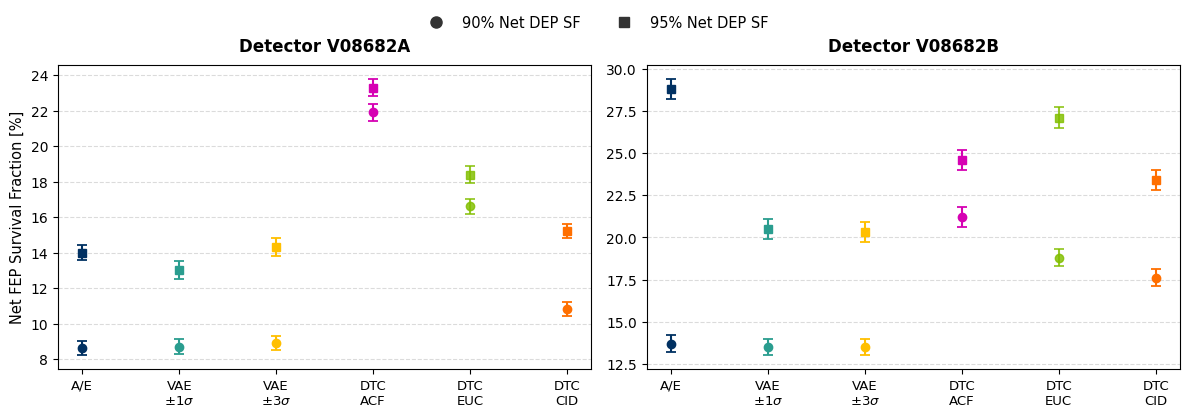

In [18]:
# -------------------------------------------------------------------------
# Plotting
# -------------------------------------------------------------------------
x = np.arange(len(MODELS))
dx = 0.  # Offset orizzontale

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))


def plot_detector(ax, title, y90, err90, y95, err95, set_ylabel=False):
  for i, col in enumerate(COLORS):
    # 90% Net DEP SF -> Marker tondo ('o')
    ax.errorbar(
        x[i] - dx,
        y90[i],
        yerr=err90[i],
        fmt='o',
        color=col,
        ecolor=col,
        elinewidth=1.5,
        capsize=3.5,
        capthick=1.3,
        markersize=6,
    )

    # 95% Net DEP SF -> Marker quadrato ('s')
    ax.errorbar(
        x[i] + dx,
        y95[i],
        yerr=err95[i],
        fmt='s',
        color=col,
        ecolor=col,
        elinewidth=1.5,
        capsize=3.5,
        capthick=1.3,
        markersize=5.5,
    )

  ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=9.5)
  if set_ylabel:
    ax.set_ylabel('Net FEP Survival Fraction [%]', fontsize=10.5)
  ax.grid(True, linestyle='--', alpha=0.45, axis='y')


# Disegna i due detector (label y attiva solo su ax1)
plot_detector(
    ax1,
    'Detector V08682A',
    y_A_90,
    err_A_90,
    y_A_95,
    err_A_95,
    set_ylabel=True,
)
plot_detector(
    ax2,
    'Detector V08682B',
    y_B_90,
    err_B_90,
    y_B_95,
    err_B_95,
    set_ylabel=False,
)

# -------------------------------------------------------------------------
# Legenda globale unica esterna (senza barre di errore)
# -------------------------------------------------------------------------
legend_handles = [
    mlines.Line2D(
        [],
        [],
        color='#333333',
        marker='o',
        linestyle='None',
        markersize=8,
        label='90% Net DEP SF',
    ),
    mlines.Line2D(
        [],
        [],
        color='#333333',
        marker='s',
        linestyle='None',
        markersize=7.5,
        label='95% Net DEP SF',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.05),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout()
plt.show()